# Painel de resultados

**Objetivo:** reunir as figuras finais do trabalho.

**Entrada:** arquivos de `data/processado/` e `models/modelo_final.json`
**Saída:** figuras em `figuras/` e `reports/resumo_resultados.md`

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

baseline = pd.read_csv("../data/processado/metricas_baseline.csv")
ablacao = pd.read_csv("../data/processado/metricas_ablacao.csv")
final = pd.read_csv("../data/processado/metricas_modelo_final.csv")
residuos = pd.read_csv("../data/processado/residuos_jogadores.csv")
residuos_base = pd.read_csv("../data/processado/residuos_baseline.csv")
importancia = pd.read_csv("../data/processado/importancia_variaveis.csv", index_col=0)

with open("../models/modelo_final.json", encoding="utf-8") as f:
    info = json.load(f)

Nomes curtos dos clubes para os rótulos dos gráficos.

In [2]:
apelidos = {
    "Clube de Regatas do Flamengo": "Flamengo", "Sociedade Esportiva Palmeiras": "Palmeiras",
    "Cruzeiro Esporte Clube": "Cruzeiro", "S. A. F. Botafogo": "Botafogo", "Clube Atlético Mineiro": "Atlético-MG",
    "Sport Club Corinthians Paulista": "Corinthians", "Esporte Clube Bahia": "Bahia",
    "Grêmio Foot-Ball Porto Alegrense": "Grêmio", "Santos Futebol Clube": "Santos", "Fluminense Football Club": "Fluminense",
    "Club de Regatas Vasco da Gama": "Vasco", "Red Bull Bragantino": "Bragantino", "Sport Club Internacional": "Internacional",
    "São Paulo Futebol Clube": "São Paulo", "Clube Atlético Paranaense": "Athletico-PR", "Fortaleza Esporte Clube": "Fortaleza",
    "Sport Club do Recife": "Sport", "Ceará Sporting Club": "Ceará", "Coritiba Foot Ball Club": "Coritiba",
    "Esporte Clube Vitória": "Vitória", "Clube do Remo": "Remo", "Associação Chapecoense de Futebol": "Chapecoense",
    "Mirasol Futebol Clube": "Mirassol", "Esporte Clube Juventude": "Juventude",
}

## Evolução dos modelos

Do piso (mediana global) até o modelo final, passando pelo baseline e por cada bloco de variáveis de contexto.

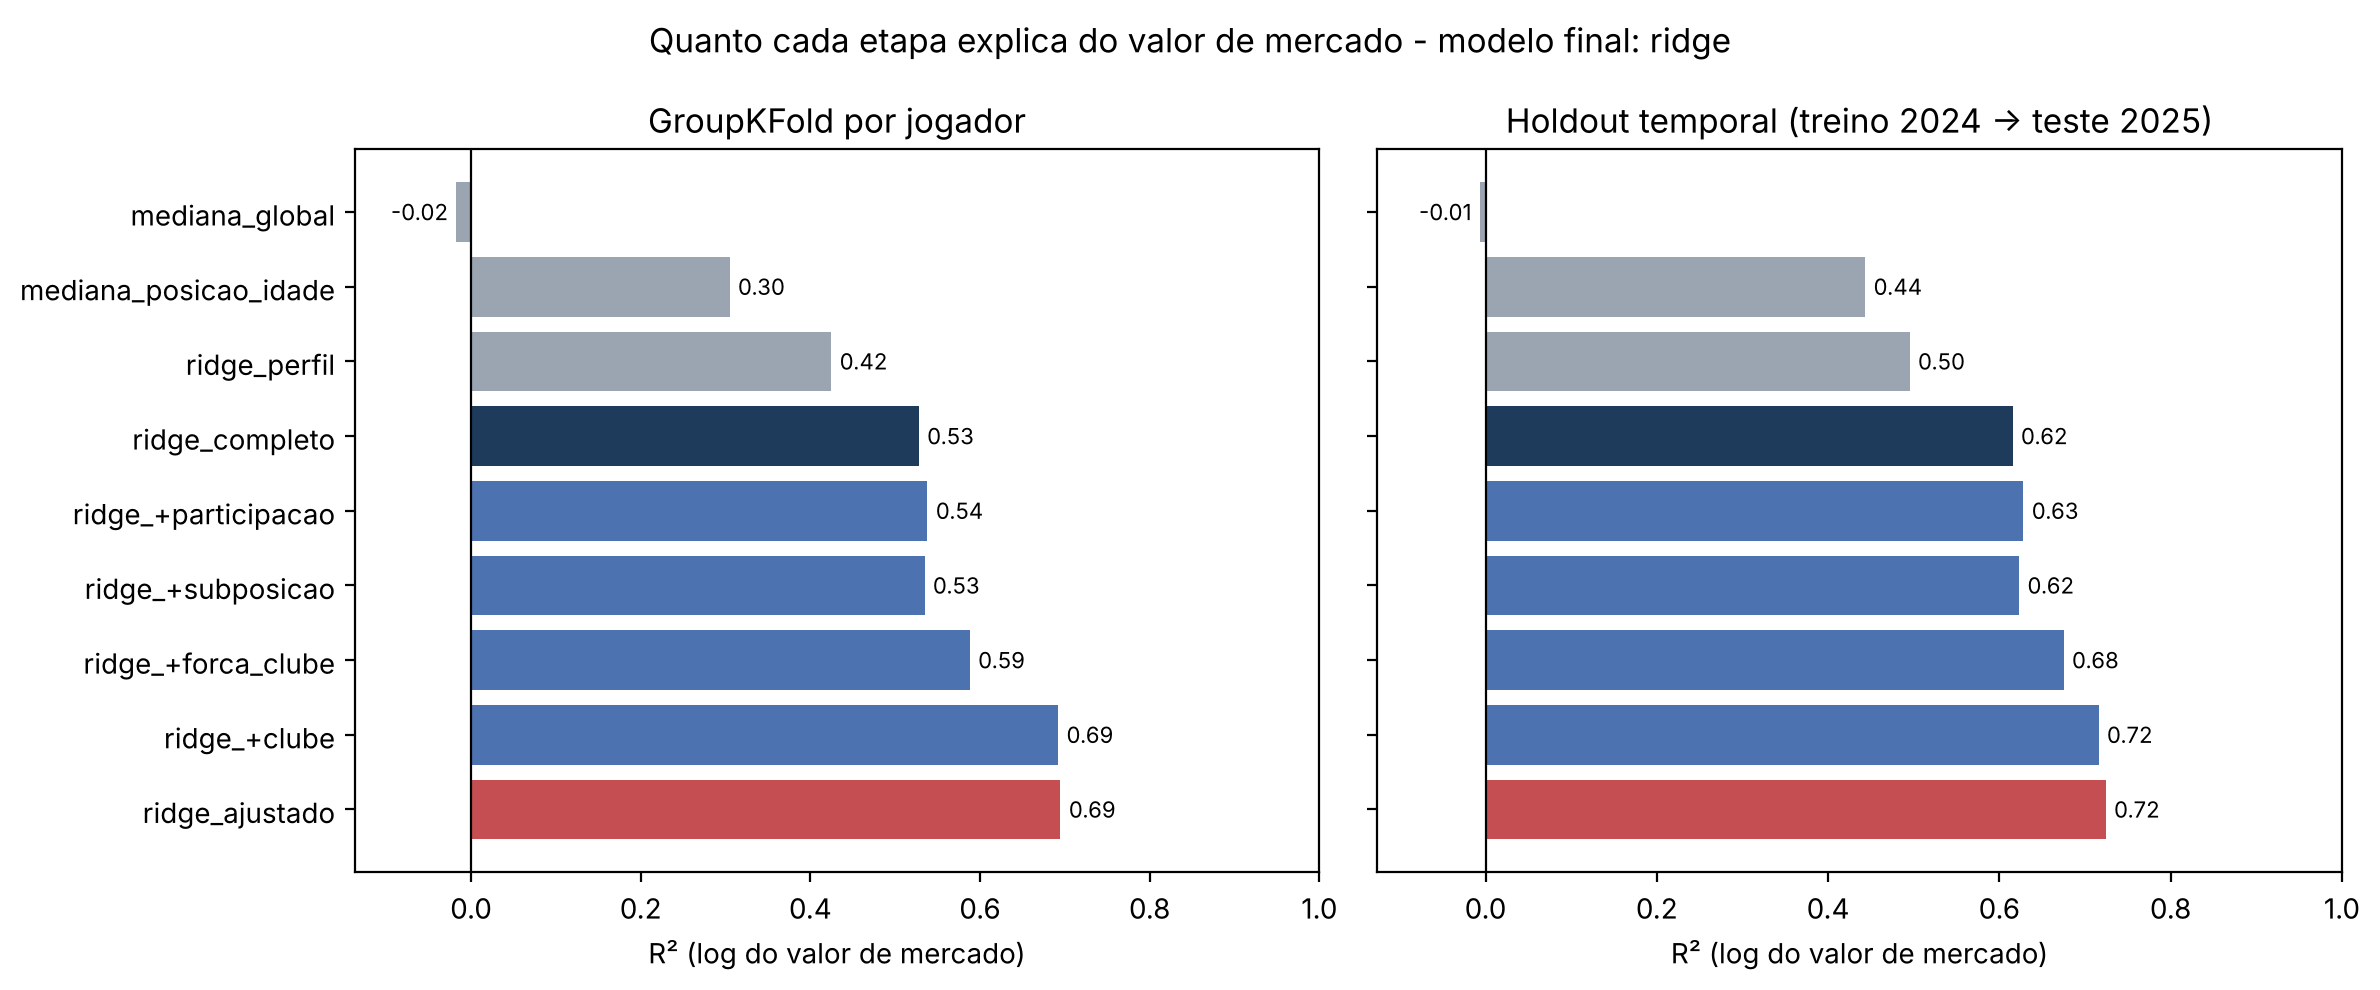

In [3]:
nome_modelo_final = final["modelo"].iloc[0]

escada = pd.concat([
    baseline[baseline["modelo"].isin(["mediana_global", "mediana_posicao_idade", "ridge_perfil"])],
    ablacao,
    final,
], ignore_index=True)

ordem = ["mediana_global", "mediana_posicao_idade", "ridge_perfil", "ridge_completo", "ridge_+participacao",
         "ridge_+subposicao", "ridge_+forca_clube", "ridge_+clube", nome_modelo_final]
cores = ["#9AA5B1"] * 3 + ["#1F3B5C"] + ["#4C72B0"] * 4 + ["#C44E52"]

fig, eixos = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for eixo, validacao, titulo in [(eixos[0], "groupkfold_5", "GroupKFold por jogador"), (eixos[1], "holdout_temporal", "Holdout temporal (treino 2024 → teste 2025)")]:
    t = escada[escada["validacao"] == validacao].drop_duplicates("modelo").set_index("modelo").loc[ordem]
    barras = eixo.barh(t.index[::-1], t["R2_log"][::-1], color=cores[::-1])
    eixo.bar_label(barras, fmt="%.2f", padding=3, fontsize=8)
    eixo.axvline(0, color="black", linewidth=0.8)
    eixo.set_xlim(min(t["R2_log"].min() - 0.12, -0.05), 1)
    eixo.set_title(titulo)
    eixo.set_xlabel("R² (log do valor de mercado)")
fig.suptitle(f"Quanto cada etapa explica do valor de mercado - modelo final: {info['nome']}")
plt.tight_layout()

fig.savefig("../figuras/painel_escada_modelos.png", bbox_inches="tight")
plt.show()

## Valor real x previsto

Escala log nos dois eixos. A faixa cinza é a zona dentro do esperado (até 50% de diferença).

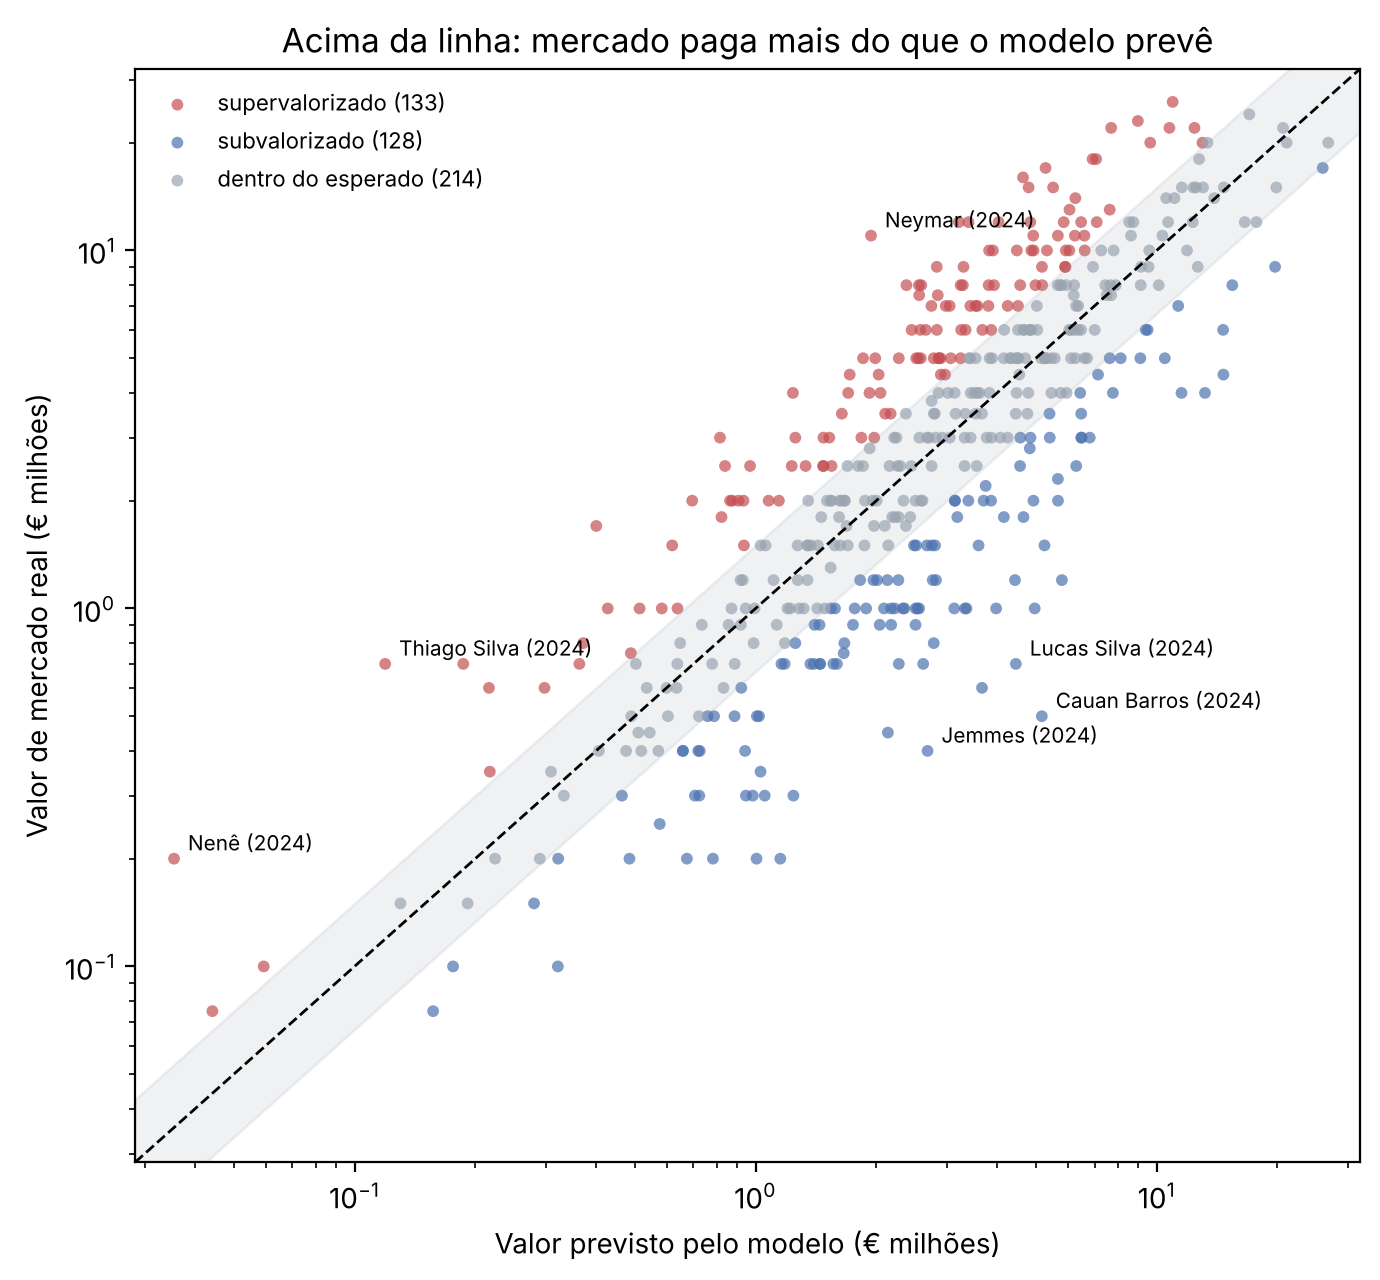

In [4]:
cores_classe = {"supervalorizado": "#C44E52", "subvalorizado": "#4C72B0", "dentro_do_esperado": "#9AA5B1"}
x = residuos["valor_previsto_eur"] / 1e6
y = residuos["valor_mercado_eur"] / 1e6
lim = np.array([min(x.min(), y.min()) * 0.8, max(x.max(), y.max()) * 1.2])

fig, eixo = plt.subplots(figsize=(7, 6.5))
for classe, cor in cores_classe.items():
    m = residuos["classificacao"] == classe
    eixo.scatter(x[m], y[m], s=18, alpha=0.7, color=cor, edgecolor="none", label=f"{classe.replace('_', ' ')} ({m.sum()})")
eixo.plot(lim, lim, color="black", linewidth=1, linestyle="--")
eixo.fill_between(lim, lim / 1.5, lim * 1.5, color="#9AA5B1", alpha=0.15)
eixo.set_xscale("log")
eixo.set_yscale("log")
eixo.set_xlim(lim)
eixo.set_ylim(lim)

destaques = pd.concat([residuos.head(3), residuos.tail(3)])
for _, r in destaques.iterrows():
    eixo.annotate(f"{r['name']} ({r['season']})", (r["valor_previsto_eur"] / 1e6, r["valor_mercado_eur"] / 1e6),
                  fontsize=7.5, xytext=(5, 3), textcoords="offset points")

eixo.set_xlabel("Valor previsto pelo modelo (€ milhões)")
eixo.set_ylabel("Valor de mercado real (€ milhões)")
eixo.set_title("Acima da linha: mercado paga mais do que o modelo prevê")
eixo.legend(frameon=False, fontsize=8)
plt.tight_layout()

fig.savefig("../figuras/painel_real_x_previsto.png", bbox_inches="tight")
plt.show()

## Maiores sub e supervalorizados

Ordenados pela razão real/previsto e não pela diferença em euros, para não aparecerem só os jogadores mais caros.

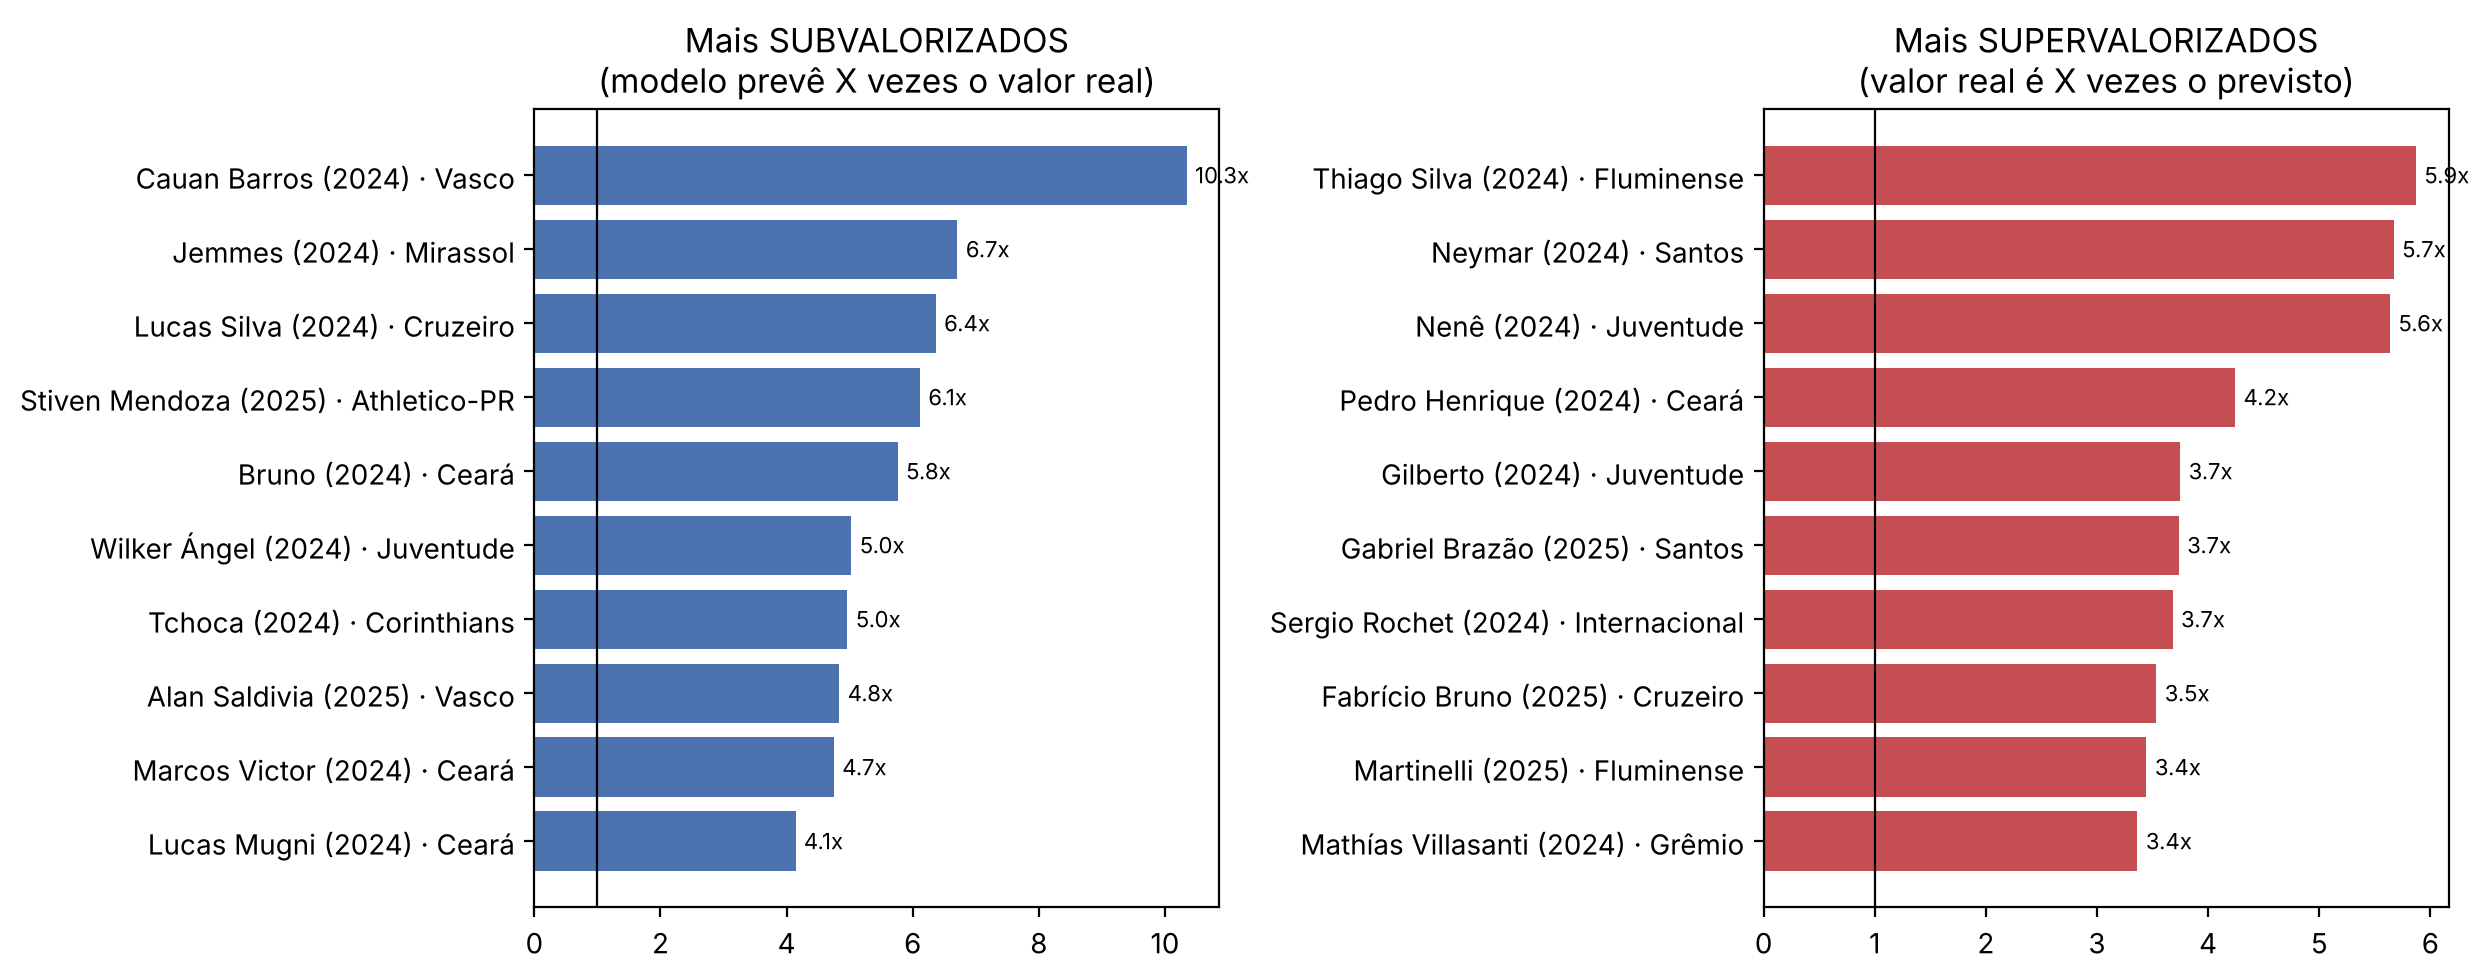

In [5]:
sub = residuos.nsmallest(10, "residuo_log")
sup = residuos.nlargest(10, "residuo_log")

rotulos_sub = [f"{n} ({s}) · {apelidos.get(c, c)}" for n, s, c in zip(sub["name"], sub["season"], sub["clube_temporada"])]
rotulos_sup = [f"{n} ({s}) · {apelidos.get(c, c)}" for n, s, c in zip(sup["name"], sup["season"], sup["clube_temporada"])]

fig, eixos = plt.subplots(1, 2, figsize=(12.5, 5))

barras = eixos[0].barh(rotulos_sub[::-1], (1 / sub["razao_real_previsto"]).to_numpy()[::-1], color="#4C72B0")
eixos[0].bar_label(barras, fmt="%.1fx", padding=3, fontsize=8)
eixos[0].axvline(1, color="black", linewidth=0.8)
eixos[0].set_title("Mais SUBVALORIZADOS\n(modelo prevê X vezes o valor real)")

barras = eixos[1].barh(rotulos_sup[::-1], sup["razao_real_previsto"].to_numpy()[::-1], color="#C44E52")
eixos[1].bar_label(barras, fmt="%.1fx", padding=3, fontsize=8)
eixos[1].axvline(1, color="black", linewidth=0.8)
eixos[1].set_title("Mais SUPERVALORIZADOS\n(valor real é X vezes o previsto)")

plt.tight_layout()

fig.savefig("../figuras/painel_top_outliers.png", bbox_inches="tight")
plt.show()

## Importância e efeito do clube

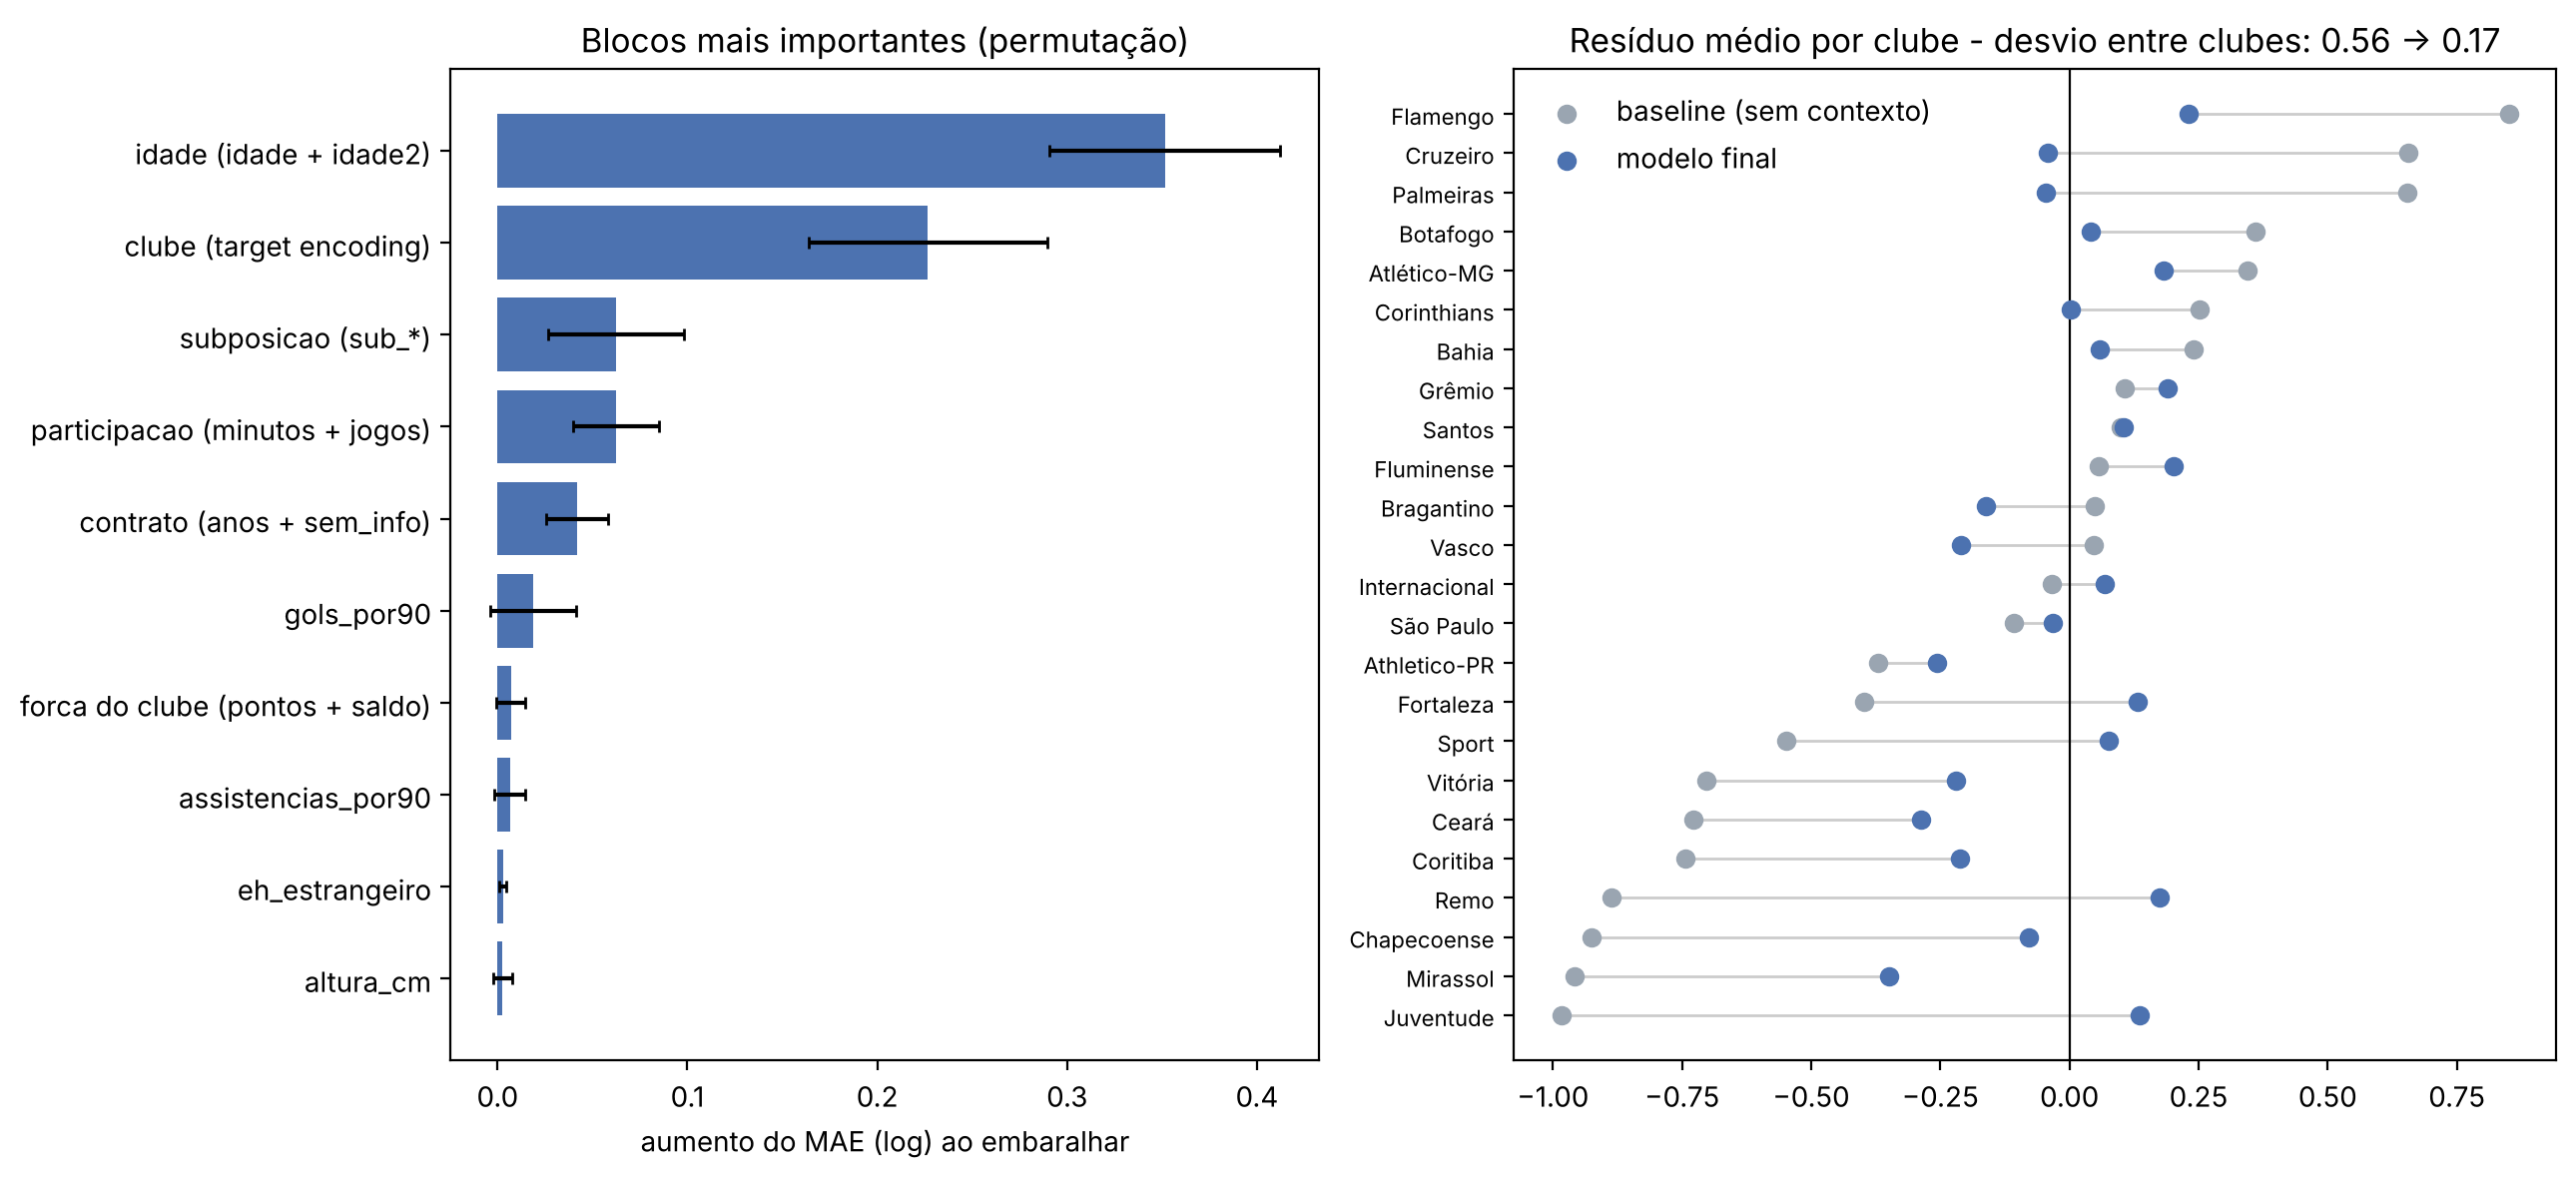

In [6]:
comp = residuos_base.merge(residuos[["season", "player_id", "residuo_log"]], on=["season", "player_id"])
clube = comp.groupby("clube_temporada")[["residuo_baseline", "residuo_log"]].mean().sort_values("residuo_baseline")
top = importancia.head(10)[::-1]
yy = np.arange(len(clube))

fig, eixos = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1, 1.2]})

eixos[0].barh(top.index, top["importancia_media"], xerr=top["desvio_entre_folds"], color="#4C72B0", capsize=2)
eixos[0].set_title("Blocos mais importantes (permutação)")
eixos[0].set_xlabel("aumento do MAE (log) ao embaralhar")

eixos[1].scatter(clube["residuo_baseline"], yy, color="#9AA5B1", label="baseline (sem contexto)", zorder=3)
eixos[1].scatter(clube["residuo_log"], yy, color="#4C72B0", label="modelo final", zorder=3)
for i in range(len(clube)):
    eixos[1].plot([clube["residuo_baseline"].iloc[i], clube["residuo_log"].iloc[i]], [i, i], color="#CCCCCC", linewidth=1, zorder=1)
eixos[1].axvline(0, color="black", linewidth=0.8)
eixos[1].set_yticks(yy, [apelidos.get(c, c) for c in clube.index], fontsize=8)
eixos[1].set_title(f"Resíduo médio por clube - desvio entre clubes: {clube['residuo_baseline'].std():.2f} → {clube['residuo_log'].std():.2f}")
eixos[1].legend(frameon=False)
plt.tight_layout()

fig.savefig("../figuras/painel_importancia_efeito_clube.png", bbox_inches="tight")
plt.show()

## Resumo

In [7]:
ref = ablacao[ablacao["modelo"] == "ridge_completo"].set_index("validacao")
fin = final.set_index("validacao")
piso = baseline[(baseline["modelo"] == "mediana_global") & (baseline["validacao"] == "holdout_temporal")]["MAE_eur"].iloc[0]
temporada = comp.groupby("season")[["residuo_baseline", "residuo_log"]].mean()

linhas = [
    "# Resumo dos resultados",
    "",
    f"**Modelo final:** {info['nome']}  ",
    f"**Hiperparâmetros:** {info['hiperparametros']}  ",
    f"**Motivo da escolha:** {info['motivo_escolha']}",
    "",
    "| validação | R² baseline | R² final | MAE log baseline | MAE log final | MAE € baseline | MAE € final |",
    "|---|---|---|---|---|---|---|",
]
for v in ["kfold_5_aleatorio", "groupkfold_5", "holdout_temporal"]:
    a, b = ref.loc[v], fin.loc[v]
    linhas.append(f"| {v} | {a['R2_log']:.3f} | {b['R2_log']:.3f} | {a['MAE_log']:.3f} | {b['MAE_log']:.3f} | € {a['MAE_eur']:,.0f} | € {b['MAE_eur']:,.0f} |")

linhas += [
    "",
    "Baseline = `ridge_completo` (perfil + desempenho + contrato, notebook 005).",
    "",
    f"Redução do MAE em euros contra o piso (mediana global) no holdout: {(1 - fin.loc['holdout_temporal', 'MAE_eur'] / piso) * 100:.1f}%",
    "",
    "## Efeito das variáveis de contexto",
    "",
    f"- Desvio do resíduo médio entre clubes: {clube['residuo_baseline'].std():.2f} → {clube['residuo_log'].std():.2f}",
]
for s, r in temporada.iterrows():
    linhas.append(f"- Resíduo médio em {s}: {r['residuo_baseline']:+.3f} → {r['residuo_log']:+.3f}")

linhas += ["", "## Blocos mais importantes", ""]
for i, v in enumerate(importancia.head(5).index, 1):
    linhas.append(f"{i}. {v}")

linhas += ["", "## Classificação dos jogadores (limiar de 50%)", ""]
for k, v in residuos["classificacao"].value_counts().items():
    linhas.append(f"- {k.replace('_', ' ')}: {v}")

texto = "\n".join(linhas)

os.makedirs("../reports", exist_ok=True)
with open("../reports/resumo_resultados.md", "w", encoding="utf-8") as f:
    f.write(texto)
print(texto)

# Resumo dos resultados

**Modelo final:** ridge  
**Hiperparâmetros:** {'modelo__alpha': 0.1}  
**Motivo da escolha:** elasticnet ganhou só 0.000 de R² sobre o Ridge, menos que o desvio entre folds (0.036). Pela parcimônia, fica o Ridge.

| validação | R² baseline | R² final | MAE log baseline | MAE log final | MAE € baseline | MAE € final |
|---|---|---|---|---|---|---|
| kfold_5_aleatorio | 0.510 | 0.699 | 0.665 | 0.517 | € 2,522,592 | € 1,978,443 |
| groupkfold_5 | 0.528 | 0.695 | 0.659 | 0.522 | € 2,503,123 | € 1,988,252 |
| holdout_temporal | 0.615 | 0.724 | 0.674 | 0.567 | € 2,967,454 | € 2,366,142 |

Baseline = `ridge_completo` (perfil + desempenho + contrato, notebook 005).

Redução do MAE em euros contra o piso (mediana global) no holdout: 42.0%

## Efeito das variáveis de contexto

- Desvio do resíduo médio entre clubes: 0.56 → 0.17
- Resíduo médio em 2024: -0.029 → -0.024
- Resíduo médio em 2025: +0.068 → +0.060

## Blocos mais importantes

1. idade (idade + idade2)
2. club